# Embedding Space Comparison: Pre-trained vs Fine-tuned

Does fine-tuning actually change the geometry of the embedding space?

Raw pre-trained models (RoBERTa-base, BERT-base) suffer from **anisotropy**: all hidden states
point in a narrow cone, so cosine similarity between any two sentences is ~0.997 regardless of
content. Class centroids sit at identical positions. Silhouette scores are near zero.

Fine-tuning for a classification task forces the model to learn a decision boundary, which
reshapes the internal geometry so that samples of the same class cluster together.

This notebook compares embedding geometry across multiple models on the same HateXplain data:
- **roberta-base** — pre-trained only, no task-specific training (anisotropic baseline)
- **bert-base-uncased** — pre-trained only, BERT family baseline
- **bert-binary-hatexplain-finetuned** — fine-tuned on hate/normal binary classification
- **shareeep/bert-base-fine-tuned-hatexplain** — fine-tuned BERT, 3-class (hate/offensive/normal)
- **shareeep/roberta-base-fine-tuned-hatexplain** — fine-tuned RoBERTa, 3-class (hate/offensive/normal)

Two pooling strategies are tested for the original models; CLS only for the new fine-tuned models:
- **CLS** — the `[CLS]`/`<s>` token hidden state
- **Rationale-weighted** — weighted mean over content tokens using HateXplain annotator scores

Metrics compared: cosine similarity, class centroid distance, silhouette score, kNN purity,
within-class variance, t-SNE layout, interactive hover visualization.


In [22]:
import json
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from collections import defaultdict

import torch
from transformers import (
    RobertaTokenizer, RobertaModel,
    BertTokenizer, BertModel,
)

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
import umap

import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots


In [23]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


Device: cpu


In [24]:
def load_hatexplain_data(file_path):
    data = []
    with open(file_path, 'r') as f:
        for line in f:
            data.append(json.loads(line))
    return data

def reconstruct_text(post_tokens):
    return ' '.join(post_tokens)

train_data = load_hatexplain_data('hatexplain/hatexplain_train.jsonl')
valid_data = load_hatexplain_data('hatexplain/hatexplain_validation.jsonl')
test_data  = load_hatexplain_data('hatexplain/hatexplain_test.jsonl')

# 3-class labels used throughout (hate=0, offensive=1, normal=2)
# For the fine-tuned binary BERT we also derive a binary label:
#   hate (0) → hatespeech, offensive (1) + normal (2) → normal
LABEL_MAP_3  = {0: 'hate', 1: 'offensive', 2: 'normal'}
LABEL_MAP_2  = {0: 'hate',  1: 'non-hate'}   # hate vs (offensive+normal)

print(f"Train: {len(train_data)}, Valid: {len(valid_data)}, Test: {len(test_data)}")


Train: 15383, Valid: 1922, Test: 1924


In [26]:
# ── Model registry ────────────────────────────────────────────────────────────
# Each entry defines everything needed to extract embeddings from one encoder.
#
# 'family'    : 'roberta' or 'bert' — controls which tokenizer class to use
# 'path'      : HuggingFace model name or local directory
# 'label_map' : which label mapping to use when colouring visualizations
# 'poolings'  : pooling strategies to run for this model; rationale pooling is
#               skipped for the HuggingFace fine-tuned models to save time since
#               CLS is the more informative metric for fine-tuned classifiers.
#
# To add another model, add an entry here — nothing else needs to change.

MODEL_CONFIGS = {
    'roberta-base\n(pre-trained)': {
        'family':    'roberta',
        'path':      'roberta-base',
        'label_map': LABEL_MAP_3,
        'poolings':  ['cls', 'rationale'],
    },
    'bert-base\n(pre-trained)': {
        'family':    'bert',
        'path':      'bert-base-uncased',
        'label_map': LABEL_MAP_3,
        'poolings':  ['cls', 'rationale'],
    },
    'bert-binary\n(fine-tuned)': {
        'family':    'bert',
        'path':      'bert-binary-hatexplain-finetuned',
        'label_map': LABEL_MAP_2,
        'poolings':  ['cls', 'rationale'],
    },
    'bert-3class\n(fine-tuned)': {
        'family':    'bert',
        'path':      'shareeep/bert-base-fine-tuned-hatexplain',
        'label_map': LABEL_MAP_3,
        'poolings':  ['cls'],
    },
    'roberta-3class\n(fine-tuned)': {
        'family':    'roberta',
        'path':      'shareeep/roberta-base-fine-tuned-hatexplain',
        'label_map': LABEL_MAP_3,
        'poolings':  ['cls'],
    },
}

# Load all tokenizers and models up front
print("Loading models...")
for name, cfg in MODEL_CONFIGS.items():
    tok_cls   = RobertaTokenizer if cfg['family'] == 'roberta' else BertTokenizer
    model_cls = RobertaModel     if cfg['family'] == 'roberta' else BertModel
    cfg['tokenizer'] = tok_cls.from_pretrained(cfg['path'])
    cfg['model']     = model_cls.from_pretrained(cfg['path']).to(DEVICE)
    cfg['model'].eval()
    print(f"  ✓ {name.replace(chr(10), ' ')}")

print("\nAll models ready.")


Loading models...


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1975.22it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  ✓ roberta-base (pre-trained)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1071.08it/s, Materializing param=pooler.dense.weight]                              
BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  ✓ bert-base (pre-trained)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 924.94it/s, Materializing param=pooler.dense.weight]                                
BertModel LOAD REPORT from: bert-binary-hatexplain-finetuned
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  ✓ bert-binary (fine-tuned)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 867.78it/s, Materializing param=pooler.dense.weight]                               
BertModel LOAD REPORT from: shareeep/bert-base-fine-tuned-hatexplain
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  ✓ bert-3class (fine-tuned)


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1942.44it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: shareeep/roberta-base-fine-tuned-hatexplain
Key                        | Status     | 
---------------------------+------------+-
classifier.out_proj.weight | UNEXPECTED | 
classifier.dense.weight    | UNEXPECTED | 
classifier.dense.bias      | UNEXPECTED | 
classifier.out_proj.bias   | UNEXPECTED | 
pooler.dense.bias          | MISSING    | 
pooler.dense.weight        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  ✓ roberta-3class (fine-tuned)

All models ready.


In [27]:
def get_embedding(text, tokenizer, model, device,
                  pooling='cls', rationale_scores=None):
    """Extract a fixed-size embedding from any BERT or RoBERTa family encoder.

    Both families use the same positional API:
      - CLS/start token is always at index 0 ([CLS] for BERT, <s> for RoBERTa)
      - SEP/end token is at the last real position ([SEP] for BERT, </s> for RoBERTa)
      - attention_mask, input_ids, token_type_ids are returned by both tokenizers
        (token_type_ids is ignored here for single-sentence inputs)

    pooling='cls'
        Return the hidden state at position 0. After all transformer layers this
        token has attended to every other token — it is a compressed whole-sequence
        summary. For fine-tuned classifiers the model was explicitly trained to
        make this token discriminative.

    pooling='rationale'
        Weighted mean over content tokens using per-word annotator scores.
        Each whitespace-split word maps to one or more subword tokens (BPE/WordPiece);
        all subwords for a word inherit that word's rationale score.
        Special tokens (CLS, SEP) always get weight 0.
        Falls back to plain mean-pool when all rationale scores are zero
        (normal-labelled posts where annotators gave no evidence tokens).
    """
    inputs = tokenizer(text, return_tensors='pt', truncation=True,
                       max_length=512, padding=True)
    inputs_on_device = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs_on_device)

    hidden         = outputs.last_hidden_state   # (1, seq_len, 768)
    attention_mask = inputs['attention_mask']

    if pooling == 'cls':
        return hidden[0, 0, :].cpu().numpy().flatten()

    # ── Rationale-weighted pooling ─────────────────────────────────────────
    words    = text.split()
    word_ids = []
    for word_idx, word in enumerate(words):
        n_sub = len(tokenizer.encode(word, add_special_tokens=False))
        word_ids.extend([word_idx] * n_sub)

    max_sub  = inputs['input_ids'].shape[1] - 2
    word_ids = word_ids[:max_sub]

    scores = (rationale_scores
              if rationale_scores and any(s > 0 for s in rationale_scores)
              else None)

    weights = [scores[w] if scores and w < len(scores) else 1.0
               for w in word_ids]

    seq_len      = inputs['input_ids'].shape[1]
    full_weights = [0.0] + weights + [0.0] * (seq_len - len(weights) - 1)
    full_weights = full_weights[:seq_len]

    att           = attention_mask[0].float().to(device)
    weight_tensor = torch.tensor(full_weights, dtype=torch.float32).to(device) * att
    weight_sum    = weight_tensor.sum()

    if weight_sum == 0:
        mask = att.unsqueeze(-1)
        return ((hidden[0] * mask).sum(0) / mask.sum()).cpu().numpy().flatten()

    w = weight_tensor.unsqueeze(-1)
    return ((hidden[0] * w).sum(0) / weight_sum).cpu().numpy().flatten()


In [28]:
def encode_dataset(data, tokenizer, model, device,
                   pooling='cls', binary_labels=False, sample_size=None):
    """Encode every sample and return rich metadata alongside the embedding.

    binary_labels=True  → collapse offensive (1) + normal (2) into non-hate (1).
    binary_labels=False → keep 3-class labels: hate=0, offensive=1, normal=2.

    Returned keys per sample:
        embedding        : 768-dim numpy array
        label            : int class label (binary or 3-class, controlled above)
        label_3          : always the original 3-class label (for display)
        text             : reconstructed post string
        highlighted      : space-joined string of tokens flagged by annotators
        agreement        : fraction of annotators who agreed on majority label
        rationale_scores : per-word float list [0.0, 1.0]
        source           : 'gab' | 'twitter' | 'unknown'
    """
    if sample_size:
        data = data[:sample_size]

    results = []
    for item in tqdm(data, desc=f"Encoding ({pooling})"):
        tokens    = item['post_tokens']
        text      = reconstruct_text(tokens)
        labels    = item['annotators']['label']
        maj_label = max(set(labels), key=labels.count)
        agreement = labels.count(maj_label) / len(labels)

        all_targets    = [t for tl in item['annotators']['target'] for t in tl]
        specific       = [t for t in all_targets if t != 'None']
        maj_target     = max(set(specific), key=specific.count) if specific else 'None'

        source = item['id'].split('_')[-1]
        if source not in ('gab', 'twitter'):
            source = 'unknown'

        # Filter to only annotator rationale arrays whose length matches the token list.
        # Some HateXplain samples have annotators with mismatched rationale lengths
        # (e.g. one annotator's list is shorter). np.mean requires a rectangular array,
        # so we drop any that don't align rather than crashing.
        rationales = item['rationales']
        valid_rationales = [r for r in rationales if len(r) == len(tokens)]
        if valid_rationales:
            rationale_scores = np.mean(valid_rationales, axis=0).tolist()
        else:
            rationale_scores = [0.0] * len(tokens)

        highlighted = ' '.join(t for t, s in zip(tokens, rationale_scores) if s > 0)

        embedding = get_embedding(text, tokenizer, model, device,
                                  pooling=pooling,
                                  rationale_scores=rationale_scores)

        # Binary: hate (0) stays 0; offensive (1) and normal (2) become 1 (non-hate)
        bin_label = 0 if maj_label == 0 else 1

        results.append({
            'embedding':        embedding,
            'label':            bin_label if binary_labels else maj_label,
            'label_3':          maj_label,
            'text':             text,
            'highlighted':      highlighted,
            'agreement':        agreement,
            'majority_target':  maj_target,
            'rationale_scores': rationale_scores,
            'source':           source,
        })
    return results


In [29]:
# ── Encode all models × pooling strategies ────────────────────────────────────
# Set SAMPLE_SIZE to e.g. 500 for quick runs; None = full dataset (~15k train + ~1.9k test).
# Each model × pooling combination is ~2-5 min on CPU for the full dataset.
#
# Already-computed entries (loaded from disk via the reload cell) are skipped
# automatically — only missing model × pooling combinations are encoded.
SAMPLE_SIZE = None

if 'arrays' not in dir():
    arrays = {}
encoded = {}

for model_name, cfg in MODEL_CONFIGS.items():
    tok    = cfg['tokenizer']
    mdl    = cfg['model']
    binary = (cfg['label_map'] is LABEL_MAP_2)

    arrays.setdefault(model_name, {})
    encoded.setdefault(model_name, {})

    for pooling in cfg['poolings']:
        if pooling in arrays[model_name]:
            print(f"  ↳ skipping {model_name.replace(chr(10), ' ')} [{pooling}] — already in arrays")
            continue

        print(f"\n{'='*55}")
        print(f"Model  : {model_name.replace(chr(10), ' ')}")
        print(f"Pooling: {pooling}")
        print(f"{'='*55}")
        encoded[model_name][pooling] = {
            'train': encode_dataset(train_data, tok, mdl, DEVICE,
                                    pooling=pooling, binary_labels=binary,
                                    sample_size=SAMPLE_SIZE),
            'test':  encode_dataset(test_data,  tok, mdl, DEVICE,
                                    pooling=pooling, binary_labels=binary,
                                    sample_size=SAMPLE_SIZE),
        }
        tr = encoded[model_name][pooling]['train']
        te = encoded[model_name][pooling]['test']
        arrays[model_name][pooling] = {
            'X_train': np.array([r['embedding'] for r in tr]),
            'X_test':  np.array([r['embedding'] for r in te]),
            'y_train': np.array([r['label']     for r in tr]),
            'y_test':  np.array([r['label']     for r in te]),
        }
        print(f"{model_name.replace(chr(10),' '):35s} [{pooling}]  "
              f"train={arrays[model_name][pooling]['X_train'].shape}  "
              f"test={arrays[model_name][pooling]['X_test'].shape}")

print("\nAll encoding complete.")


  ↳ skipping roberta-base (pre-trained) [cls] — already in arrays
  ↳ skipping roberta-base (pre-trained) [rationale] — already in arrays
  ↳ skipping bert-base (pre-trained) [cls] — already in arrays
  ↳ skipping bert-base (pre-trained) [rationale] — already in arrays
  ↳ skipping bert-binary (fine-tuned) [cls] — already in arrays
  ↳ skipping bert-binary (fine-tuned) [rationale] — already in arrays

Model  : bert-3class (fine-tuned)
Pooling: cls


Encoding (cls): 100%|██████████| 1924/1924 [01:10<00:00, 27.36it/s]


bert-3class (fine-tuned)            [cls]  train=(15383, 768)  test=(1924, 768)

Model  : roberta-3class (fine-tuned)
Pooling: cls


Encoding (cls): 100%|██████████| 1924/1924 [01:06<00:00, 29.13it/s]

roberta-3class (fine-tuned)         [cls]  train=(15383, 768)  test=(1924, 768)

All encoding complete.


In [30]:

# ── Save / load embeddings ─────────────────────────────────────────────────────
# Encoding takes ~1 hour on CPU for the full dataset.
# This cell merges the current `arrays` into any existing save file so that
# previously computed embeddings are never overwritten.
import pickle

SAVE_PATH = 'embeddings/embedding_comparison_arrays.pkl'
os.makedirs('embeddings', exist_ok=True)

# Merge with existing file if present
if os.path.exists(SAVE_PATH):
    with open(SAVE_PATH, 'rb') as f:
        existing = pickle.load(f)
    for model_name, pooling_dict in arrays.items():
        existing.setdefault(model_name, {}).update(pooling_dict)
    to_save = existing
else:
    to_save = arrays

with open(SAVE_PATH, 'wb') as f:
    pickle.dump(to_save, f)
print(f"Saved arrays to {SAVE_PATH}")
for model_name in to_save:
    for pooling in to_save[model_name]:
        shape = to_save[model_name][pooling]['X_train'].shape
        print(f"  {model_name.replace(chr(10), ' '):35s} [{pooling}]  X_train={shape}")


Saved arrays to embeddings/embedding_comparison_arrays.pkl
  roberta-base (pre-trained)          [cls]  X_train=(15383, 768)
  roberta-base (pre-trained)          [rationale]  X_train=(15383, 768)
  bert-base (pre-trained)             [cls]  X_train=(15383, 768)
  bert-base (pre-trained)             [rationale]  X_train=(15383, 768)
  bert-binary (fine-tuned)            [cls]  X_train=(15383, 768)
  bert-binary (fine-tuned)            [rationale]  X_train=(15383, 768)
  bert-3class (fine-tuned)            [cls]  X_train=(15383, 768)
  roberta-3class (fine-tuned)         [cls]  X_train=(15383, 768)


In [31]:

# ── Reload arrays from disk (skips re-encoding for already-computed models) ───
# This cell is safe to run on every full notebook run:
#   • If the pickle exists  → loads it into `arrays`; the encoding loop below
#     will skip any model × pooling that is already present.
#   • If no pickle yet      → initialises `arrays` as empty; the encoding loop
#     runs everything from scratch.
#
# Note: `encoded` (full metadata with text/hover info) is NOT saved to keep
# file sizes manageable. Re-run the encoding loop if you need it for Plotly.
import pickle

SAVE_PATH = 'embeddings/embedding_comparison_arrays.pkl'

if os.path.exists(SAVE_PATH):
    with open(SAVE_PATH, 'rb') as f:
        arrays = pickle.load(f)
    print(f"Loaded arrays from {SAVE_PATH}")
    for model_name in arrays:
        for pooling in arrays[model_name]:
            shape = arrays[model_name][pooling]['X_train'].shape
            print(f"  {model_name.replace(chr(10), ' '):35s} [{pooling}]  X_train={shape}")
else:
    arrays = {}
    print(f"No saved arrays found at {SAVE_PATH} — will encode from scratch.")


Loaded arrays from embeddings/embedding_comparison_arrays.pkl
  roberta-base (pre-trained)          [cls]  X_train=(15383, 768)
  roberta-base (pre-trained)          [rationale]  X_train=(15383, 768)
  bert-base (pre-trained)             [cls]  X_train=(15383, 768)
  bert-base (pre-trained)             [rationale]  X_train=(15383, 768)
  bert-binary (fine-tuned)            [cls]  X_train=(15383, 768)
  bert-binary (fine-tuned)            [rationale]  X_train=(15383, 768)
  bert-3class (fine-tuned)            [cls]  X_train=(15383, 768)
  roberta-3class (fine-tuned)         [cls]  X_train=(15383, 768)


In [32]:
# ── Geometry metrics for every model × pooling ────────────────────────────────
# Silhouette: how well each sample fits its own cluster vs the nearest other.
# kNN purity: fraction of a sample's 10 nearest neighbours sharing its label.
# Centroid cosine: mean cosine similarity between class centroids (lower = more separated).
# Within-class variance: mean variance across all 768 dims within each class.

np.random.seed(42)
SIL_SAMPLE = 1000
KNN_SAMPLE = 500
K          = 10

rows = []

for model_name, cfg in MODEL_CONFIGS.items():
    for pooling in cfg['poolings']:
        arr     = arrays[model_name][pooling]
        X_tr    = arr['X_train']
        y_tr    = arr['y_train']
        classes = np.unique(y_tr)

        # Silhouette (subsample for speed)
        sil_idx = np.random.choice(len(X_tr), min(SIL_SAMPLE, len(X_tr)), replace=False)
        sil     = silhouette_score(X_tr[sil_idx], y_tr[sil_idx])

        # kNN purity
        knn_idx = np.random.choice(len(X_tr), min(KNN_SAMPLE, len(X_tr)), replace=False)
        purity_scores = []
        for idx in knn_idx:
            sims      = cosine_similarity(X_tr[idx].reshape(1, -1), X_tr)[0]
            sims[idx] = -1
            top_k     = np.argsort(sims)[-K:]
            purity_scores.append(np.sum(y_tr[top_k] == y_tr[idx]) / K)
        knn_purity = np.mean(purity_scores)

        # Mean inter-centroid cosine similarity (lower = more separated)
        centroids     = {c: X_tr[y_tr == c].mean(axis=0) for c in classes}
        centroid_sims = []
        cls_list      = sorted(centroids.keys())
        for i in range(len(cls_list)):
            for j in range(i + 1, len(cls_list)):
                s = cosine_similarity([centroids[cls_list[i]]], [centroids[cls_list[j]]])[0][0]
                centroid_sims.append(s)
        mean_centroid_sim = np.mean(centroid_sims)

        # Within-class variance
        wc_var = np.mean([np.mean(np.var(X_tr[y_tr == c], axis=0)) for c in classes])

        rows.append({
            'Model':               model_name.replace('\n', ' '),
            'Pooling':             pooling,
            'Silhouette':          round(float(sil), 4),
            'kNN purity':          round(float(knn_purity), 4),
            'Centroid sim (mean)': round(float(mean_centroid_sim), 6),
            'Within-class var':    round(float(wc_var), 6),
        })
        print(f"{model_name.replace(chr(10), ' '):35s} [{pooling}]  "
              f"sil={sil:.4f}  knn={knn_purity:.4f}  "
              f"ctrd={mean_centroid_sim:.6f}  var={wc_var:.6f}")

metrics_df = pd.DataFrame(rows)
print("\n")
print(metrics_df.to_string(index=False))
print("\nKey: Silhouette ↑ better | kNN purity ↑ better | Centroid sim ↓ better | Var ↓ better")


roberta-base (pre-trained)          [cls]  sil=-0.0028  knn=0.4478  ctrd=0.999963  var=0.000471
roberta-base (pre-trained)          [rationale]  sil=0.0125  knn=0.5700  ctrd=0.997843  var=0.012205
bert-base (pre-trained)             [cls]  sil=-0.0044  knn=0.4100  ctrd=0.997052  var=0.051495
bert-base (pre-trained)             [rationale]  sil=0.0229  knn=0.6886  ctrd=0.956891  var=0.060711
bert-binary (fine-tuned)            [cls]  sil=0.1812  knn=0.8270  ctrd=0.572314  var=0.160208
bert-binary (fine-tuned)            [rationale]  sil=0.1683  knn=0.8594  ctrd=0.727932  var=0.097708
bert-3class (fine-tuned)            [cls]  sil=0.1554  knn=0.7432  ctrd=0.391726  var=0.154612
roberta-3class (fine-tuned)         [cls]  sil=0.1771  knn=0.7210  ctrd=0.636226  var=0.159959


                      Model   Pooling  Silhouette  kNN purity  Centroid sim (mean)  Within-class var
 roberta-base (pre-trained)       cls     -0.0028      0.4478             0.999963          0.000471
 roberta-base (p

Pre-trained t-SNE sample: 1500 points (stratified, ~500 per class)
  hate: 500
  offensive: 500
  normal: 500

Running t-SNE for pre-trained models...
  done: roberta-base (pre-trained) [cls]
  done: roberta-base (pre-trained) [rationale]
  done: bert-base (pre-trained) [cls]
  done: bert-base (pre-trained) [rationale]


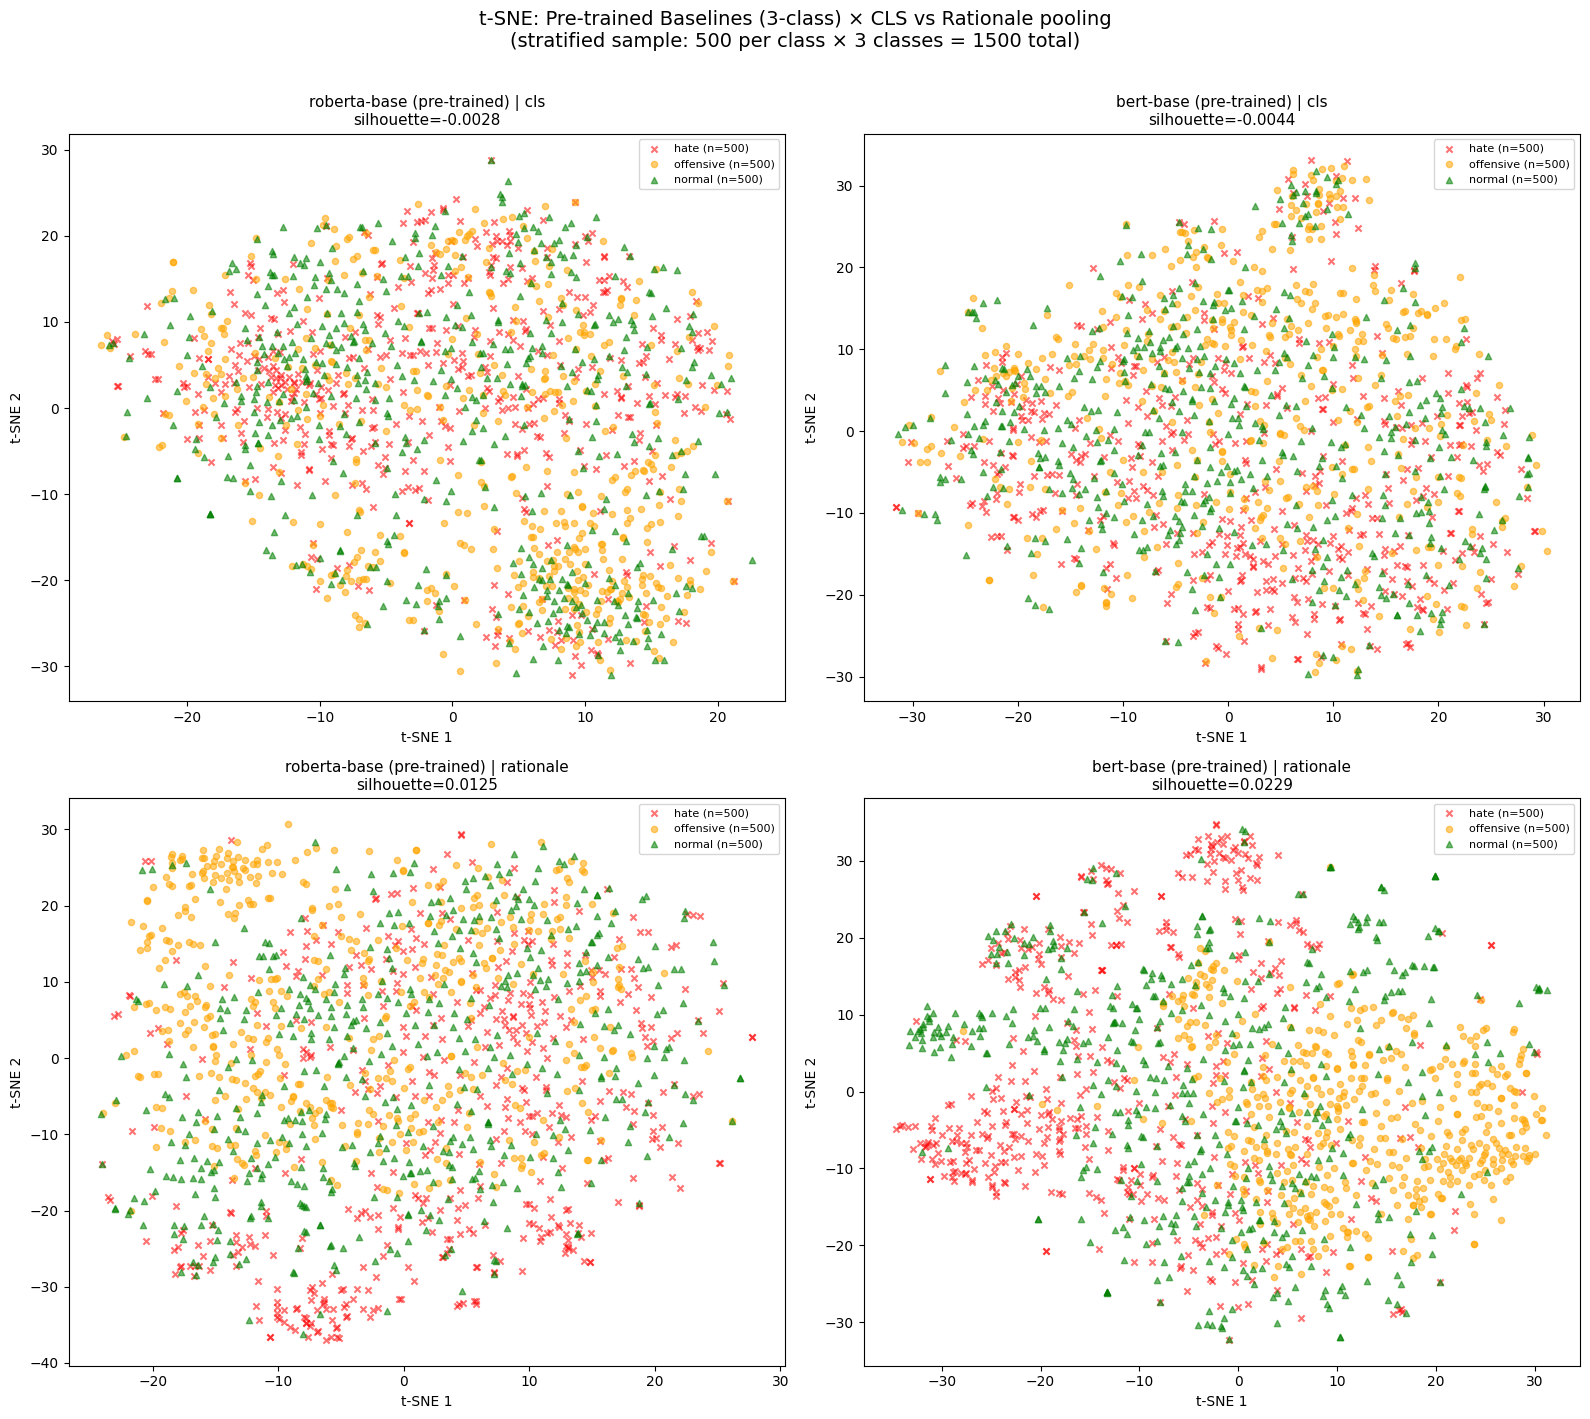

Saved to embeddings/tsne_pretrained_comparison.png


In [33]:

# ── t-SNE: Pre-trained models (3-class: hate / offensive / normal) ─────────────
# Stratified 500/500/500 across the three classes (1500 total).
# Same indices used for both pre-trained models so layout differences reflect
# embedding geometry, not sampling variance.

TSNE_SAMPLE = 1500
np.random.seed(42)

pretrained_names = ['roberta-base\n(pre-trained)', 'bert-base\n(pre-trained)']

# Stratify on 3-class labels from the first pre-trained model
ref_model   = pretrained_names[0]
y_ref       = arrays[ref_model]['cls']['y_train']
classes_ref = sorted(np.unique(y_ref))
n_per_class = TSNE_SAMPLE // len(classes_ref)   # = 500

tsne_idx_3class = np.concatenate([
    np.random.choice(np.where(y_ref == c)[0], min(n_per_class, (y_ref == c).sum()), replace=False)
    for c in classes_ref
])
np.random.shuffle(tsne_idx_3class)

print(f"Pre-trained t-SNE sample: {len(tsne_idx_3class)} points (stratified, ~{n_per_class} per class)")
for c in classes_ref:
    print(f"  {LABEL_MAP_3[c]}: {(y_ref[tsne_idx_3class] == c).sum()}")

print("\nRunning t-SNE for pre-trained models...")
tsne      = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
tsne_2d   = {}
for model_name in pretrained_names:
    tsne_2d[model_name] = {}
    for pooling in ['cls', 'rationale']:
        X_sub = arrays[model_name][pooling]['X_train'][tsne_idx_3class]
        tsne_2d[model_name][pooling] = tsne.fit_transform(X_sub)
        print(f"  done: {model_name.replace(chr(10),' ')} [{pooling}]")

# ── Plot: 2 rows (pooling) × 2 columns (model) ────────────────────────────────
COLORS_3 = {0: 'red', 1: 'orange', 2: 'green'}
MARKERS  = {0: 'x',   1: 'o',      2: '^'}

fig, axes = plt.subplots(2, len(pretrained_names), figsize=(8 * len(pretrained_names), 14))

for col, model_name in enumerate(pretrained_names):
    for row, pooling in enumerate(['cls', 'rationale']):
        ax    = axes[row][col]
        X_2d  = tsne_2d[model_name][pooling]
        y_sub = arrays[model_name][pooling]['y_train'][tsne_idx_3class]

        for cls in sorted(np.unique(y_sub)):
            mask = y_sub == cls
            ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                       c=COLORS_3[cls], marker=MARKERS.get(cls, 'o'),
                       label=f"{LABEL_MAP_3[cls]} (n={mask.sum()})",
                       alpha=0.55, s=20)

        sil_val = metrics_df.loc[
            (metrics_df['Model']   == model_name.replace('\n', ' ')) &
            (metrics_df['Pooling'] == pooling), 'Silhouette'
        ].values[0]

        ax.set_title(f"{model_name.replace(chr(10), ' ')} | {pooling}\nsilhouette={sil_val:.4f}", fontsize=11)
        ax.set_xlabel('t-SNE 1')
        ax.set_ylabel('t-SNE 2')
        ax.legend(fontsize=8)

plt.suptitle('t-SNE: Pre-trained Baselines (3-class) × CLS vs Rationale pooling\n'
             f'(stratified sample: {n_per_class} per class × 3 classes = {len(tsne_idx_3class)} total)',
             fontsize=14, y=1.01)
plt.tight_layout()
os.makedirs('embeddings', exist_ok=True)
plt.savefig('embeddings/tsne_pretrained_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to embeddings/tsne_pretrained_comparison.png")


Binary t-SNE sample: 1500 points (stratified, ~750 per class)
  hate: 750
  non-hate: 750

Running t-SNE for fine-tuned binary BERT...
  done: bert-binary (fine-tuned) [cls]
  done: bert-binary (fine-tuned) [rationale]


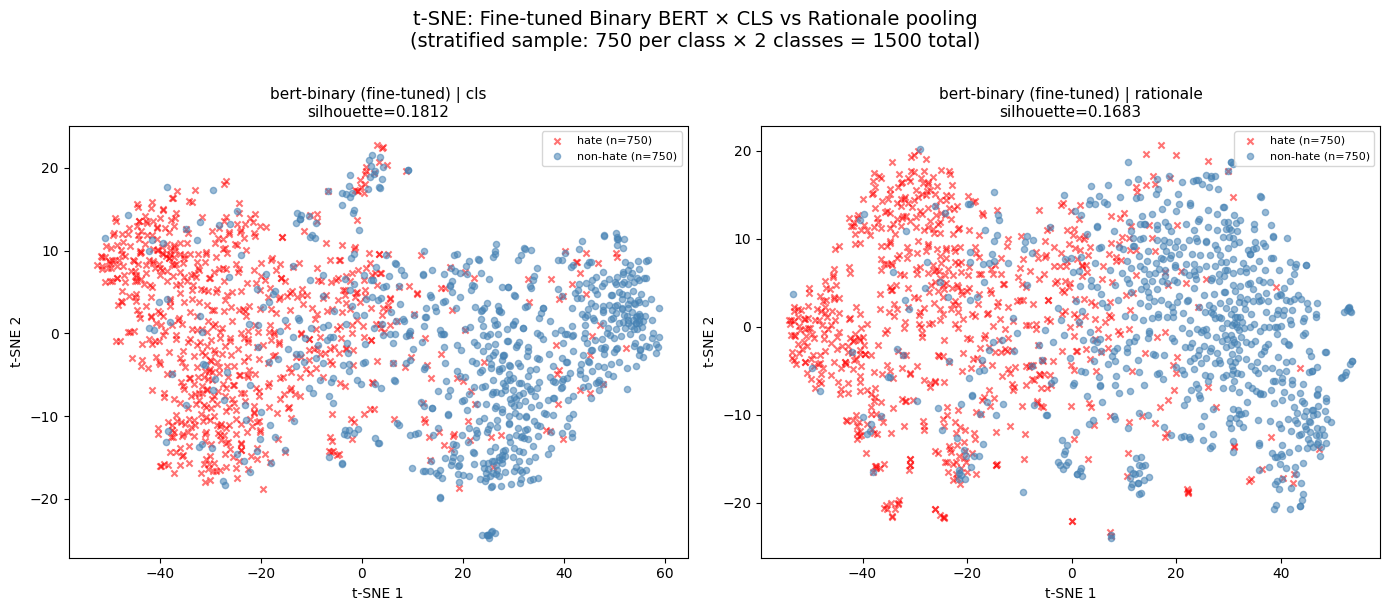

Saved to embeddings/tsne_binary_comparison.png


In [21]:

# ── t-SNE: Fine-tuned binary BERT (hate vs non-hate) ──────────────────────────
# Stratified 750/750 across the two binary classes (1500 total).
# Stratified on the binary labels from the fine-tuned model itself.

TSNE_SAMPLE_BIN = 1500
np.random.seed(42)

binary_name     = 'bert-binary\n(fine-tuned)'
y_bin           = arrays[binary_name]['cls']['y_train']   # 0=hate, 1=non-hate
classes_bin     = sorted(np.unique(y_bin))
n_per_class_bin = TSNE_SAMPLE_BIN // len(classes_bin)     # = 750

tsne_idx_binary = np.concatenate([
    np.random.choice(np.where(y_bin == c)[0], min(n_per_class_bin, (y_bin == c).sum()), replace=False)
    for c in classes_bin
])
np.random.shuffle(tsne_idx_binary)

print(f"Binary t-SNE sample: {len(tsne_idx_binary)} points (stratified, ~{n_per_class_bin} per class)")
for c in classes_bin:
    print(f"  {LABEL_MAP_2[c]}: {(y_bin[tsne_idx_binary] == c).sum()}")

print("\nRunning t-SNE for fine-tuned binary BERT...")
tsne_bin    = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
tsne_2d_bin = {}
for pooling in ['cls', 'rationale']:
    X_sub = arrays[binary_name][pooling]['X_train'][tsne_idx_binary]
    tsne_2d_bin[pooling] = tsne_bin.fit_transform(X_sub)
    print(f"  done: {binary_name.replace(chr(10),' ')} [{pooling}]")

# ── Plot: 1 row × 2 columns (one per pooling strategy) ────────────────────────
COLORS_2 = {0: 'red', 1: 'steelblue'}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for col, pooling in enumerate(['cls', 'rationale']):
    ax    = axes[col]
    X_2d  = tsne_2d_bin[pooling]
    y_sub = arrays[binary_name][pooling]['y_train'][tsne_idx_binary]

    for cls in sorted(np.unique(y_sub)):
        mask = y_sub == cls
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                   c=COLORS_2[cls], marker='o' if cls else 'x',
                   label=f"{LABEL_MAP_2[cls]} (n={mask.sum()})",
                   alpha=0.55, s=20)

    sil_val = metrics_df.loc[
        (metrics_df['Model']   == binary_name.replace('\n', ' ')) &
        (metrics_df['Pooling'] == pooling), 'Silhouette'
    ].values[0]

    ax.set_title(f"{binary_name.replace(chr(10), ' ')} | {pooling}\nsilhouette={sil_val:.4f}", fontsize=11)
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.legend(fontsize=8)

plt.suptitle('t-SNE: Fine-tuned Binary BERT × CLS vs Rationale pooling\n'
             f'(stratified sample: {n_per_class_bin} per class × 2 classes = {len(tsne_idx_binary)} total)',
             fontsize=14, y=1.01)
plt.tight_layout()
os.makedirs('embeddings', exist_ok=True)
plt.savefig('embeddings/tsne_binary_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to embeddings/tsne_binary_comparison.png")


Fine-tuned 3-class t-SNE sample: 1500 points (stratified, ~500 per class)
  hate: 500
  offensive: 500
  normal: 500

Running t-SNE for fine-tuned 3-class models (CLS)...
  done: bert-3class (fine-tuned) [cls]
  done: roberta-3class (fine-tuned) [cls]


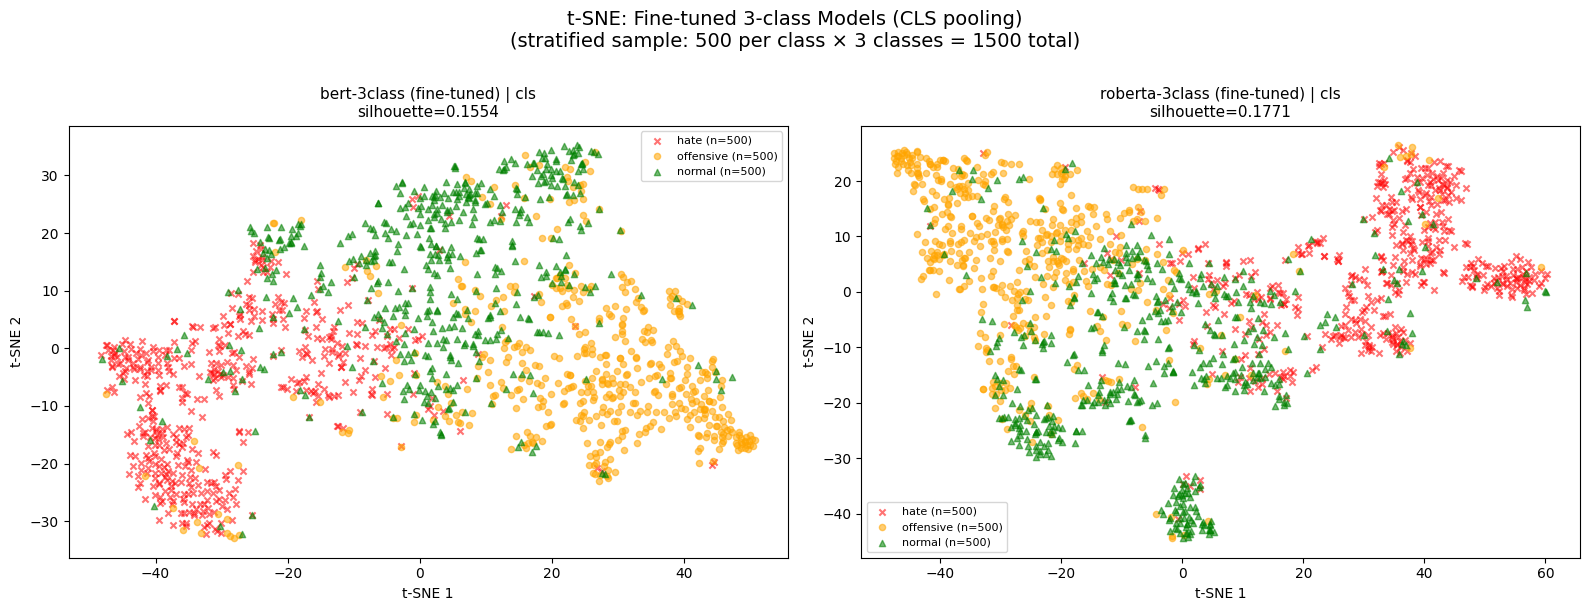

Saved to embeddings/tsne_finetuned3class_comparison.png


In [34]:

# ── t-SNE: Fine-tuned 3-class models (CLS only) ───────────────────────────────
# Stratified 500/500/500 (1500 total) using the same reference posts as the
# pre-trained cell so the layouts are directly comparable.
# Only CLS pooling here — rationale pooling is skipped for speed.

TSNE_SAMPLE_FT = 1500
np.random.seed(42)

finetuned_3class_names = ['bert-3class\n(fine-tuned)', 'roberta-3class\n(fine-tuned)']

# Stratify on 3-class labels from the bert-3class model
ref_ft    = finetuned_3class_names[0]
y_ref_ft  = arrays[ref_ft]['cls']['y_train']
classes_ft = sorted(np.unique(y_ref_ft))
n_per_class_ft = TSNE_SAMPLE_FT // len(classes_ft)   # = 500

tsne_idx_ft = np.concatenate([
    np.random.choice(np.where(y_ref_ft == c)[0], min(n_per_class_ft, (y_ref_ft == c).sum()), replace=False)
    for c in classes_ft
])
np.random.shuffle(tsne_idx_ft)

print(f"Fine-tuned 3-class t-SNE sample: {len(tsne_idx_ft)} points (stratified, ~{n_per_class_ft} per class)")
for c in classes_ft:
    print(f"  {LABEL_MAP_3[c]}: {(y_ref_ft[tsne_idx_ft] == c).sum()}")

print("\nRunning t-SNE for fine-tuned 3-class models (CLS)...")
tsne_ft   = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
tsne_2d_ft = {}
for model_name in finetuned_3class_names:
    X_sub = arrays[model_name]['cls']['X_train'][tsne_idx_ft]
    tsne_2d_ft[model_name] = tsne_ft.fit_transform(X_sub)
    print(f"  done: {model_name.replace(chr(10),' ')} [cls]")

# ── Plot: 1 row × 2 columns (one per model) ───────────────────────────────────
COLORS_3 = {0: 'red', 1: 'orange', 2: 'green'}
MARKERS  = {0: 'x',   1: 'o',      2: '^'}

fig, axes = plt.subplots(1, len(finetuned_3class_names), figsize=(8 * len(finetuned_3class_names), 6))

for col, model_name in enumerate(finetuned_3class_names):
    ax    = axes[col]
    X_2d  = tsne_2d_ft[model_name]
    y_sub = arrays[model_name]['cls']['y_train'][tsne_idx_ft]

    for cls in sorted(np.unique(y_sub)):
        mask = y_sub == cls
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                   c=COLORS_3[cls], marker=MARKERS.get(cls, 'o'),
                   label=f"{LABEL_MAP_3[cls]} (n={mask.sum()})",
                   alpha=0.55, s=20)

    sil_val = metrics_df.loc[
        (metrics_df['Model']   == model_name.replace('\n', ' ')) &
        (metrics_df['Pooling'] == 'cls'), 'Silhouette'
    ].values[0]

    ax.set_title(f"{model_name.replace(chr(10), ' ')} | cls\nsilhouette={sil_val:.4f}", fontsize=11)
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.legend(fontsize=8)

plt.suptitle('t-SNE: Fine-tuned 3-class Models (CLS pooling)\n'
             f'(stratified sample: {n_per_class_ft} per class × 3 classes = {len(tsne_idx_ft)} total)',
             fontsize=14, y=1.01)
plt.tight_layout()
os.makedirs('embeddings', exist_ok=True)
plt.savefig('embeddings/tsne_finetuned3class_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to embeddings/tsne_finetuned3class_comparison.png")


## Interactive Embedding Explorer

Static scatter plots show whether clusters separate — interactive plots show **why**.

Hover over any point to see:
- The full post text
- The highlighted tokens that annotators flagged as evidence
- The label and annotator agreement score
- The source platform (Gab / Twitter)

Use the legend to toggle classes on/off. Zoom into dense regions to find:
- Hate posts misplaced in the normal cluster — often sarcasm or ambiguous phrasing
- Normal posts in the hate cluster — may reveal annotation noise or edge cases
- The degree to which the fine-tuned model separates hate from non-hate vs pre-trained models

Select a model and pooling strategy to explore using the dropdowns below.


In [ ]:
# removed

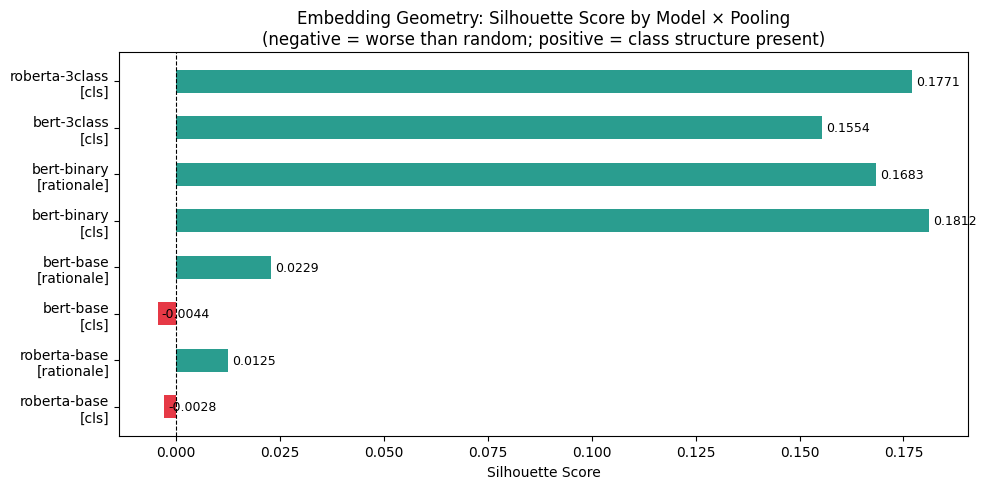


All metrics:
                      Model   Pooling  Silhouette  kNN purity  Centroid sim (mean)  Within-class var
 roberta-base (pre-trained)       cls     -0.0028      0.4478             0.999963          0.000471
 roberta-base (pre-trained) rationale      0.0125      0.5700             0.997843          0.012205
    bert-base (pre-trained)       cls     -0.0044      0.4100             0.997052          0.051495
    bert-base (pre-trained) rationale      0.0229      0.6886             0.956891          0.060711
   bert-binary (fine-tuned)       cls      0.1812      0.8270             0.572314          0.160208
   bert-binary (fine-tuned) rationale      0.1683      0.8594             0.727932          0.097708
   bert-3class (fine-tuned)       cls      0.1554      0.7432             0.391726          0.154612
roberta-3class (fine-tuned)       cls      0.1771      0.7210             0.636226          0.159959

Silhouette scores ranked (higher = better separated clusters):
  bert-binary

In [35]:

# ── Summary bar chart: silhouette scores across all configurations ─────────────
fig, ax = plt.subplots(figsize=(10, 5))

chart_labels = [f"{r['Model'].split('(')[0].strip()}\n[{r['Pooling']}]"
                for _, r in metrics_df.iterrows()]
values  = metrics_df['Silhouette'].values
colors  = ['#e63946' if v < 0 else '#2a9d8f' for v in values]

bars = ax.barh(chart_labels, values, color=colors, height=0.5)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Silhouette Score')
ax.set_title('Embedding Geometry: Silhouette Score by Model × Pooling\n'
             '(negative = worse than random; positive = class structure present)')

for bar, val in zip(bars, values):
    ax.text(val + 0.001, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('embeddings/silhouette_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Text summary table ────────────────────────────────────────────────────────
print("\nAll metrics:")
print(metrics_df.to_string(index=False))

print("\nSilhouette scores ranked (higher = better separated clusters):")
ranked = metrics_df[['Model', 'Pooling', 'Silhouette']].sort_values('Silhouette', ascending=False)
for _, row in ranked.iterrows():
    bar   = '█' * int(abs(row['Silhouette']) * 200)
    sign  = '+' if row['Silhouette'] >= 0 else '-'
    print(f"  {row['Model']:35s} [{row['Pooling']:8s}]  {sign}{abs(row['Silhouette']):.4f}  {bar}")

print("\nInterpretation guide:")
print("  silhouette ≈ -0.003  → completely unstructured (pre-trained RoBERTa/BERT)")
print("  silhouette >  0.1    → visible but overlapping clusters")
print("  silhouette >  0.3    → well-separated clusters")
print("  Fine-tuned BERT should score noticeably higher than the pre-trained baselines.")
